# Student Performance Analysis
What drives first-semester marks? This notebook cleans a synthetic dataset (255 rows, 11 columns) and answers four questions:
1. What is the overall performance of the batch?
2. Do attendance and study hours affect marks?
3. Does performance differ by branch, gender, residence or tutoring?
4. Which students are at risk (average marks below 50)?

## 1. Load and inspect the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("../data/raw/student_performance.csv")
print(df.shape)
df.head()

(255, 11)


,Student_ID,Gender,Branch,Residence,Attendance_Pct,Study_Hours_Per_Week,Sleep_Hours,Tutoring,Maths_Marks,Physics_Marks,Programming_Marks
0,S1133,Male,IT,Day Scholar,62.5,14.1,6.6,No,52.0,60.0,58.0
1,S1248,Male,IT,Day Scholar,67.8,8.8,5.4,No,42.0,51.0,65.0
2,S1225,Female,CSE,Day Scholar,80.5,13.5,7.0,No,64.0,58.0,65.0
3,S1025,Male,cse,Hostel,70.1,10.6,8.1,Yes,38.0,62.0,60.0
4,S1058,Female,IT,Day Scholar,79.7,12.7,8.0,Yes,54.0,56.0,63.0


In [2]:
df.info()
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Student_ID            255 non-null    str    
 1   Gender                255 non-null    str    
 2   Branch                255 non-null    str    
 3   Residence             255 non-null    str    
 4   Attendance_Pct        251 non-null    float64
 5   Study_Hours_Per_Week  251 non-null    float64
 6   Sleep_Hours           251 non-null    float64
 7   Tutoring              255 non-null    str    
 8   Maths_Marks           251 non-null    float64
 9   Physics_Marks         251 non-null    float64
 10  Programming_Marks     251 non-null    float64
dtypes: float64(6), str(5)
memory usage: 22.0 KB

Missing values:
 Student_ID              0
Gender                  0
Branch                  0
Residence               0
Attendance_Pct          4
Study_Hours_Per_Week    4
Sleep_Hours         

,Attendance_Pct,Study_Hours_Per_Week,Sleep_Hours,Maths_Marks,Physics_Marks,Programming_Marks
count,251.000000,251.000000,251.000000,251.000000,251.000000,251.000000
mean,74.805976,11.806375,6.713944,53.772908,54.529880,59.278884
std,11.087247,4.174412,1.040425,12.333378,10.871711,10.967311
min,35.000000,1.000000,4.000000,21.000000,20.000000,33.000000
25%,68.200000,9.050000,6.100000,46.000000,48.000000,52.000000
50%,75.400000,11.900000,6.700000,53.000000,55.000000,60.000000
75%,81.450000,14.600000,7.400000,60.000000,62.000000,66.000000
max,100.000000,22.800000,9.000000,145.000000,91.000000,99.000000


## 2. Clean the data
Drop duplicates, standardise text, replace the impossible mark (above 100) with a missing value, then fill missing numbers with the column median.

In [3]:
df = df.drop_duplicates().copy()

for col in ["Gender", "Branch", "Residence", "Tutoring"]:
    df[col] = df[col].str.strip().str.title()
df["Branch"] = df["Branch"].str.upper()

mark_cols = ["Maths_Marks", "Physics_Marks", "Programming_Marks"]
for col in mark_cols:
    df.loc[df[col] > 100, col] = np.nan

num_cols = ["Attendance_Pct", "Study_Hours_Per_Week", "Sleep_Hours"] + mark_cols
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

print("Rows after cleaning:", len(df))
print("Missing values left:", df.isna().sum().sum())
print(df["Gender"].unique(), df["Branch"].unique(), df["Residence"].unique(), df["Tutoring"].unique())

Rows after cleaning: 250
Missing values left: 0
<StringArray>
['Male', 'Female']
Length: 2, dtype: str <StringArray>
['IT', 'CSE', 'ME', 'ECE']
Length: 4, dtype: str <StringArray>
['Day Scholar', 'Hostel']
Length: 2, dtype: str <StringArray>
['No', 'Yes']
Length: 2, dtype: str


## 3. Create new columns

In [4]:
df["Average_Marks"] = df[mark_cols].mean(axis=1).round(1)
df["Total_Marks"] = df[mark_cols].sum(axis=1)

def band(m):
    if m >= 70: return "Distinction"
    if m >= 60: return "First Class"
    if m >= 50: return "Pass"
    return "At Risk"

df["Result_Band"] = df["Average_Marks"].apply(band)
df["Attendance_Group"] = pd.cut(df["Attendance_Pct"], [0, 60, 75, 100],
                                labels=["Low (<60)", "Medium (60-75)", "High (>75)"])
df["At_Risk"] = df["Average_Marks"] < 50

df.to_csv("../data/processed/student_performance_clean.csv", index=False)
df[["Student_ID", "Average_Marks", "Result_Band"]].head()

,Student_ID,Average_Marks,Result_Band
0,S1133,56.7,Pass
1,S1248,52.7,Pass
2,S1225,62.3,First Class
3,S1025,53.3,Pass
4,S1058,57.7,Pass


## 4. Overall performance of the batch

count    250.00
mean      55.84
std        7.72
min       38.30
25%       50.30
50%       56.70
75%       60.30
max       75.00
Name: Average_Marks, dtype: float64

Result band counts:
 Result_Band
Pass           127
At Risk         57
First Class     52
Distinction     14
Name: count, dtype: int64


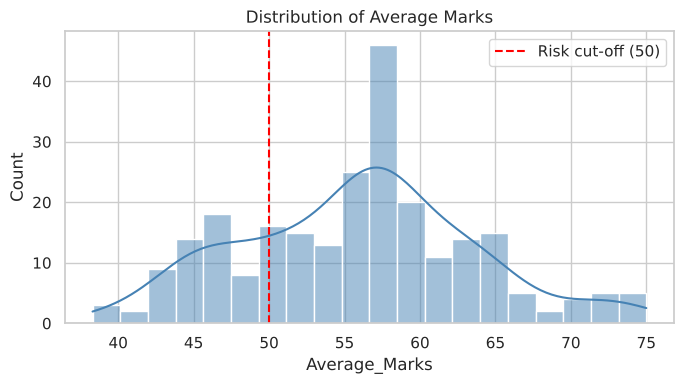

In [5]:
print(df["Average_Marks"].describe().round(2))
print("\nResult band counts:\n", df["Result_Band"].value_counts())

plt.figure(figsize=(7, 4))
sns.histplot(df["Average_Marks"], bins=20, kde=True, color="steelblue")
plt.axvline(50, color="red", linestyle="--", label="Risk cut-off (50)")
plt.title("Distribution of Average Marks")
plt.legend()
plt.tight_layout()
plt.savefig("../images/average_marks_histogram.png", dpi=150)
plt.show()

## 5. Do attendance and study hours affect marks?

Attendance_Pct          0.49
Study_Hours_Per_Week    0.63
Sleep_Hours            -0.07
Average_Marks           1.00
Name: Average_Marks, dtype: float64


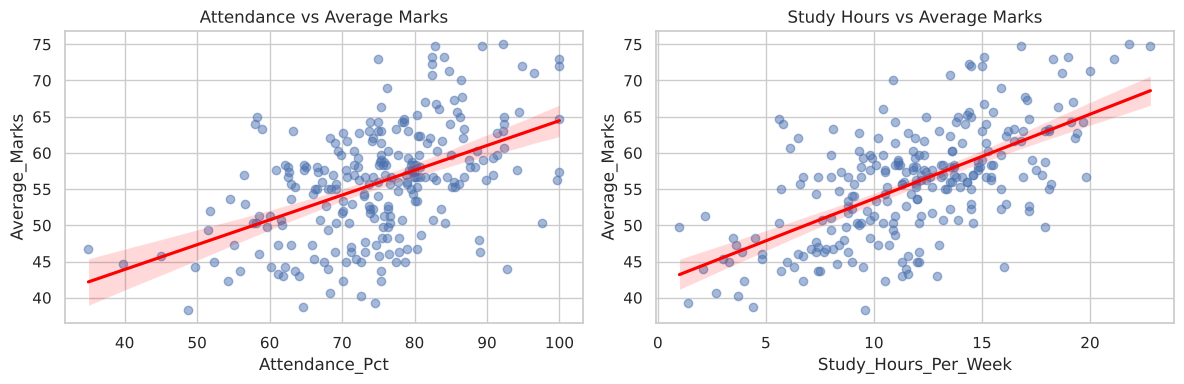

In [6]:
print(df[["Attendance_Pct", "Study_Hours_Per_Week", "Sleep_Hours", "Average_Marks"]].corr().round(2)["Average_Marks"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.regplot(data=df, x="Attendance_Pct", y="Average_Marks", ax=axes[0],
            scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
axes[0].set_title("Attendance vs Average Marks")
sns.regplot(data=df, x="Study_Hours_Per_Week", y="Average_Marks", ax=axes[1],
            scatter_kws={"alpha": 0.5}, line_kws={"color": "red"})
axes[1].set_title("Study Hours vs Average Marks")
plt.tight_layout()
plt.savefig("../images/attendance_study_scatter.png", dpi=150)
plt.show()

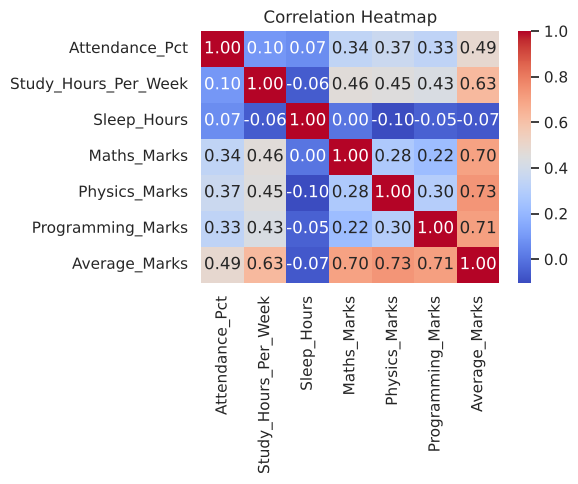

In [7]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[["Attendance_Pct", "Study_Hours_Per_Week", "Sleep_Hours",
                "Maths_Marks", "Physics_Marks", "Programming_Marks", "Average_Marks"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("../images/correlation_heatmap.png", dpi=150)
plt.show()

Correlation shows association, not cause.

## 6. Performance by group

Branch
CSE    56.1
ECE    55.0
IT     55.4
ME     57.6
Name: Average_Marks, dtype: float64 

Gender
Female    56.1
Male      55.5
Name: Average_Marks, dtype: float64 

Residence
Day Scholar    56.0
Hostel         55.6
Name: Average_Marks, dtype: float64 

Tutoring
No     55.0
Yes    57.1
Name: Average_Marks, dtype: float64 



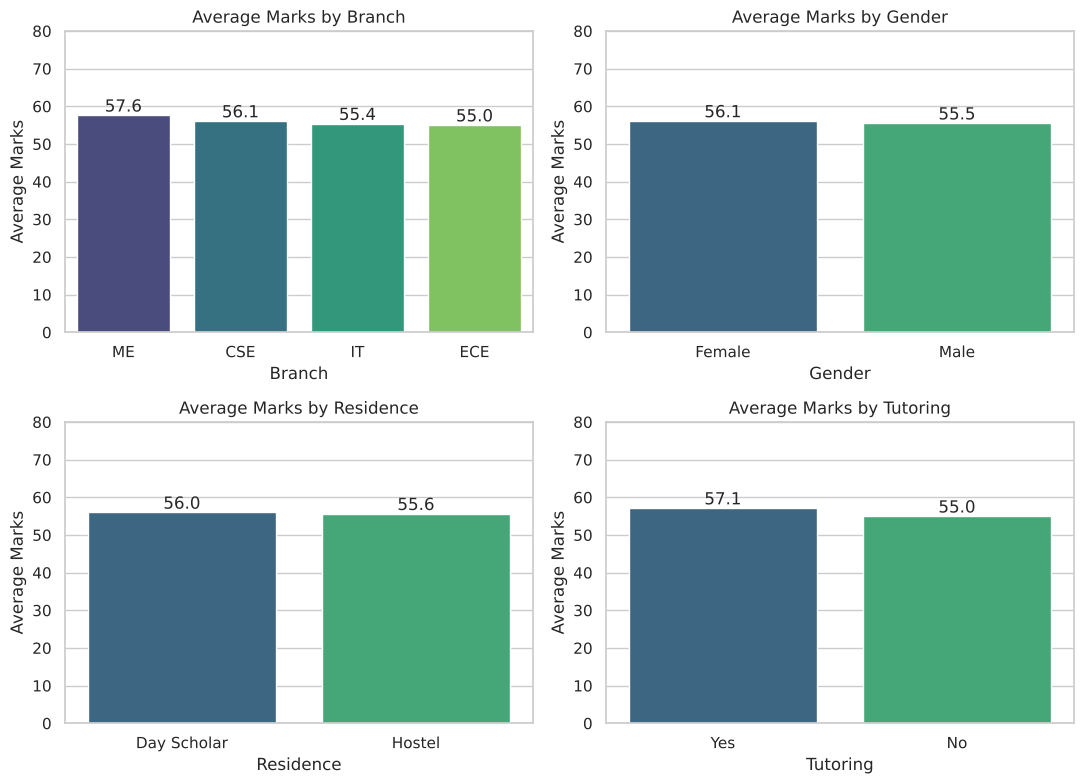

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.flat, ["Branch", "Gender", "Residence", "Tutoring"]):
    order = df.groupby(col)["Average_Marks"].mean().sort_values(ascending=False)
    sns.barplot(x=order.index, y=order.values, ax=ax, palette="viridis", hue=order.index, legend=False)
    ax.set_title(f"Average Marks by {col}")
    ax.set_ylabel("Average Marks")
    ax.set_ylim(0, 80)
    for i, v in enumerate(order.values):
        ax.text(i, v + 1, f"{v:.1f}", ha="center")
plt.tight_layout()
plt.savefig("../images/marks_by_group.png", dpi=150)
plt.show()

for col in ["Branch", "Gender", "Residence", "Tutoring"]:
    print(df.groupby(col)["Average_Marks"].mean().round(1), "\n")

## 7. At-risk students (average marks below 50)

In [9]:
at_risk = df[df["At_Risk"]].sort_values("Average_Marks")
print(f"{len(at_risk)} students at risk ({len(at_risk) / len(df):.1%} of the batch)")
print("\nAt-risk rate by attendance group:")
print(df.groupby("Attendance_Group", observed=True)["At_Risk"].mean().round(3))
at_risk[["Student_ID", "Branch", "Attendance_Pct", "Study_Hours_Per_Week", "Average_Marks"]].head(15)

57 students at risk (22.8% of the batch)

At-risk rate by attendance group:
Attendance_Group
Low (<60)         0.545
Medium (60-75)    0.281
High (>75)        0.136
Name: At_Risk, dtype: float64


,Student_ID,Branch,Attendance_Pct,Study_Hours_Per_Week,Average_Marks
218,S1184,CSE,48.8,9.6,38.3
19,S1079,IT,64.6,4.4,38.7
80,S1122,ECE,74.6,1.4,39.3
178,S1209,CSE,72.6,3.7,40.3
148,S1049,CSE,68.3,2.7,40.7
160,S1108,CSE,54.3,6.7,42.3
119,S1050,CSE,70.1,4.0,42.3
158,S1077,CSE,75.4,10.5,42.3
188,S1232,IT,64.0,12.9,43.0
88,S1042,ECE,61.9,11.3,43.0


## 8. Extension tasks

In [10]:
# Top 10 students by Total_Marks
top10 = df.sort_values("Total_Marks", ascending=False).head(10)
top10[["Student_ID", "Branch", "Total_Marks", "Average_Marks"]].reset_index(drop=True)

,Student_ID,Branch,Total_Marks,Average_Marks
0,S1074,CSE,225.0,75.0
1,S1188,CSE,224.0,74.7
2,S1246,ME,224.0,74.7
3,S1166,IT,220.0,73.3
4,S1131,CSE,220.0,73.3
5,S1116,ME,219.0,73.0
6,S1004,ECE,219.0,73.0
7,S1177,IT,217.0,72.3
8,S1091,CSE,216.0,72.0
9,S1211,ECE,216.0,72.0


In [11]:
# Sleep hours vs marks
print("Correlation (Sleep_Hours vs Average_Marks):", round(df["Sleep_Hours"].corr(df["Average_Marks"]), 2))
df["Sleep_Group"] = pd.cut(df["Sleep_Hours"], [0, 6, 7.5, 12], labels=["<6 h", "6-7.5 h", ">7.5 h"])
print(df.groupby("Sleep_Group", observed=True)["Average_Marks"].mean().round(1))

Correlation (Sleep_Hours vs Average_Marks): -0.07
Sleep_Group
<6 h       57.3
6-7.5 h    55.5
>7.5 h     55.0
Name: Average_Marks, dtype: float64


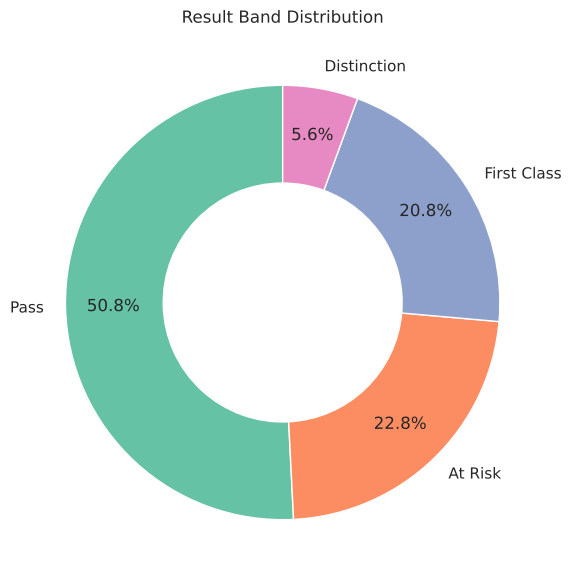

In [12]:
# Donut chart of Result_Band
counts = df["Result_Band"].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90, pctdistance=0.78,
        wedgeprops={"width": 0.45}, colors=sns.color_palette("Set2"))
plt.title("Result Band Distribution")
plt.tight_layout()
plt.savefig("../images/result_band_donut.png", dpi=150)
plt.show()

## 9. Insights and recommendations
Run the notebook, then write your own findings here using the numbers above. Suggested structure:
- **Overall:** mean and spread of Average_Marks, share in each Result_Band.
- **Attendance and study hours:** strength of correlation; students with low attendance are more often at risk.
- **Groups:** which branch / tutoring group differs most, and whether the gap is large or small.
- **Recommendations:** early mentoring for students with attendance below 60%, promote tutoring, set study-hour targets.
- **Limitation:** the data is synthetic, and correlation is not causation.